# Group Equivariant Neural Networks

# 1. Notion of algebraic Group

Symmetry operations can be collected together in a **group** structure:
> A group $(G, \cdot)$ is a set $G$ together with a binary operation (the *group law*) $\cdot : G \times G \to G$ which satisfies the following axioms:
*   *Closure* — group operation is "internal": $\forall a, b \in G$ we have $a \cdot b \in G$.
*   *Associativity*:  $\forall a, b, c \in G \quad a \cdot (b \cdot c) = (a \cdot b) \cdot c$
*   *Identity*:  $\exists e \in G : \forall g \in G \quad g \cdot e = e \cdot g = g$
*   *Inverse*:   $\forall g \in G \ \ \exists g^{-1} \in G: \quad g g^{-1} = g^{-1} g = e$

Note that a group is *not* necessarily commutative, i.e. $a \cdot b \neq b \cdot a$ generally.
A group with commutative operations is called an **abelian** group.

### Continous example

Translation Group. Translations $T_\mathbf{v}$ by a vector $\mathbf{v}$ form a grup with translation "product" $T_\mathbf{w}T_\mathbf{v}=T_\mathbf{v+w}$, inverse $T^{-1}_\mathbf{v}=T_{-\mathbf{v}}$, and identity element $T_\mathbf{0}$.

### Discrete example
Consider the group $G$ of rotations by multiples of $\frac{\pi}{2}$.
This group contains $4$ elements and is called the **cyclic group** of order $4$; we usually indicate it with $G=C_4$:
$$
  C_4 = \{R_{0}, R_{\frac{\pi}{2}}, R_{\pi}, R_{3\frac{\pi}{2}} \} = \{ R_{r \frac{\pi}{2}} \ |\ r = 0, 1, 2, 3\}.
$$

# 2. Equivariance

In many physically relevant situations, a model (e.g., a system’s Hamiltonian or Lagrangian) preserves certain symmetries — that is, it remains **invariant** under the action of a symmetry group. For example, a Hamiltonian may be translationally invariant or commute with the angular momentum operator. Since angular momentum generates rotations, commuting with it means that the system has rotational symmetry. In this sense, the angular momentum operator $J$ is a *generator* of the rotation group: $R(\theta)=e^{-i\theta J/\hbar}$.

### model invariance
Let's say we have a physical model $M$. We say that the model is *invariant* under a symmetry group operation $g$ iff $M(gx)=M(x)$.

### model equivariance
Sometimes — especially in the context of deep learning — we use a slightly weaker (more general) assumption: $M(gx)=L_gM(x)$, which we call equivariance.
If $L_g$ is the identity operator, then we recover invariance. Note that $L_g$ is a $g$ operator *representation* in the model's outputs space.




# 3. Affine transformation
In the laboratory we will deal with translations and rotations. Their *matrix representations* are as follows:
$$
T(v_x,v_y)=
\begin{pmatrix}
1 & 0 & v_x \\
0 & 1 & v_y \\
\end{pmatrix},
\quad
R(\theta)=
\begin{pmatrix}
\cos\theta & -\sin\theta & 0 \\
\sin\theta & \cos\theta & 0\\
\end{pmatrix},
$$
where we use a general *affine matrix* formulation. In case of $C_4$ group we have four generators:
$$
\{
\begin{pmatrix}
1 & 0 \\
0 & 1 \\
\end{pmatrix},
\begin{pmatrix}
0 & -1 \\
1 & 0 \\
\end{pmatrix},
\begin{pmatrix}
-1 & 0 \\
0 & -1 \\
\end{pmatrix},
\begin{pmatrix}
0 & 1 \\
-1 & 0 \\
\end{pmatrix}\}.
$$

# First experiments
1. Prove that convolutional layer is equivariant with respect to translations.
2. What about CNN equivariance with respect to $C_4$ group operations?

In [3]:
import numpy as np
import torch
import torch.nn.functional as F

import matplotlib.pyplot as plt

def translate(x, v):
    return x.roll((v[0],v[1]), dims=(-2, -1))

# A 90-deg rotation operation, where r is the number of rotations applied (i.e., r = 0, 1, 2, 3) indexing the $C_4$ group elements.
def rotate(x, r):
    return x.rot90(r, dims=(-2, -1))

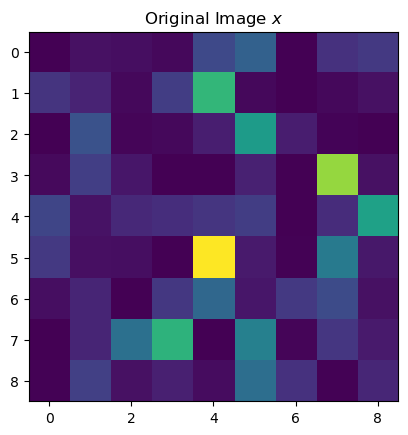

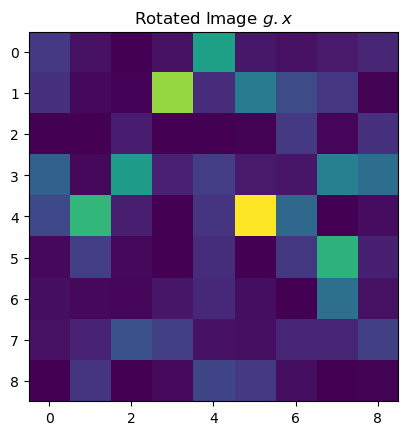

In [3]:
x = torch.randn(1, 1, 9, 9)**2

r = 1
gx = rotate(x, r)

plt.imshow(x[0, 0].numpy())
plt.title('Original Image $x$')
plt.show()

plt.imshow(gx[0, 0].numpy())
plt.title('Rotated Image $g.x$')
plt.show()

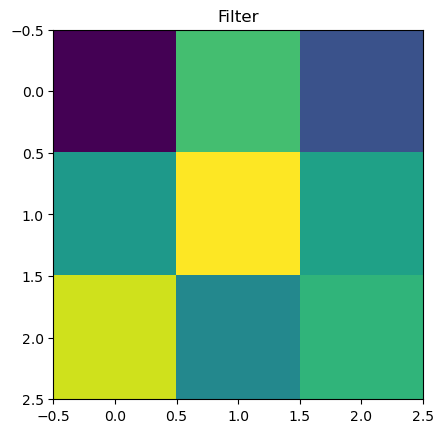

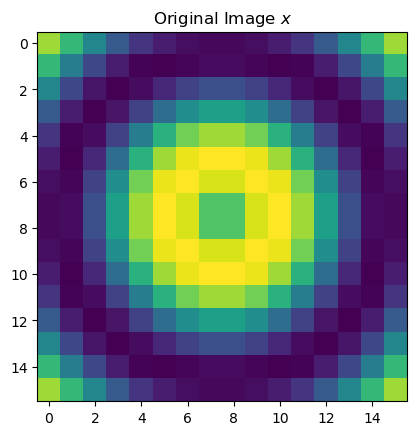

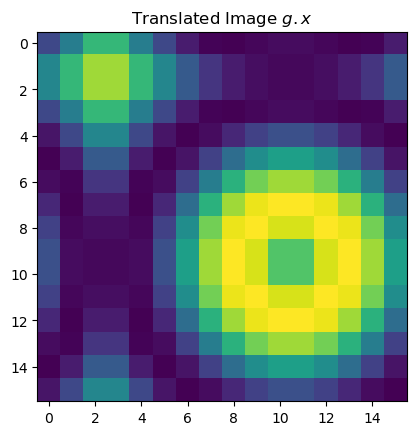

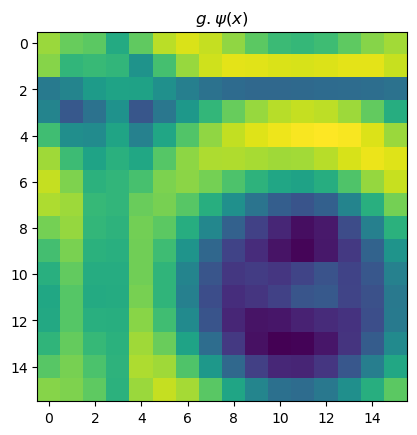

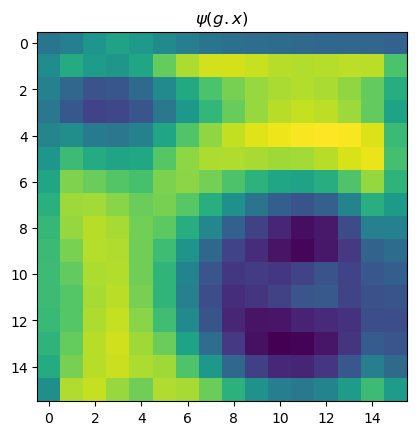

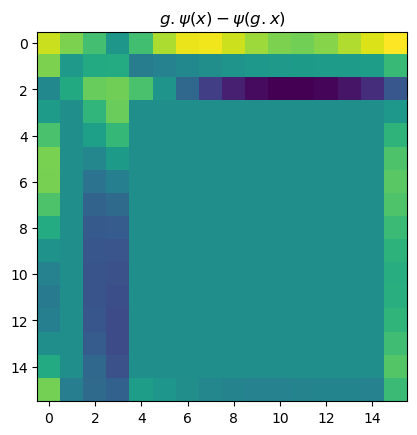

In [8]:
filter3x3 = torch.randn(1, 1, 3, 3)

plt.imshow(filter3x3[0, 0].numpy())
plt.title('Filter')
plt.show()

# generate some input...
xs = torch.linspace(-5, 5, steps=16)
xg, yg = torch.meshgrid(xs, xs, indexing='xy')
x = torch.sin(torch.sqrt(xg * xg + yg * yg))
x = x[None, None, ...]

v = (2,3)  # translate by vector v=(2,3) (periodic b.c.)
gx = translate(x, v)

plt.imshow(x[0, 0].numpy())
plt.title('Original Image $x$')
plt.show()

plt.imshow(gx[0, 0].numpy())
plt.title('Translated Image $g.x$')
plt.show()

# ...then test equivariance:
psi_x = torch.conv2d(x, filter3x3, bias=None, padding=1)
#psi_x = torch.conv2d(F.pad(x, (1, 1, 1, 1), mode="circular"), filter3x3, bias=None, padding=0)
psi_gx = torch.conv2d(gx, filter3x3, bias=None, padding=1)
#psi_gx = torch.conv2d(F.pad(gx, (1, 1, 1, 1), mode="circular"), filter3x3, bias=None, padding=0)

g_psi_x = translate(psi_x, v)

plt.imshow(g_psi_x[0, 0].numpy())
plt.title('$g.\\psi(x)$')
plt.show()

plt.imshow(psi_gx[0, 0].numpy())
plt.title('$\\psi(g.x)$')
plt.show()

plt.imshow((g_psi_x-psi_gx)[0, 0].numpy())
plt.title('$g.\\psi(x)-\\psi(g.x)$')
plt.show()

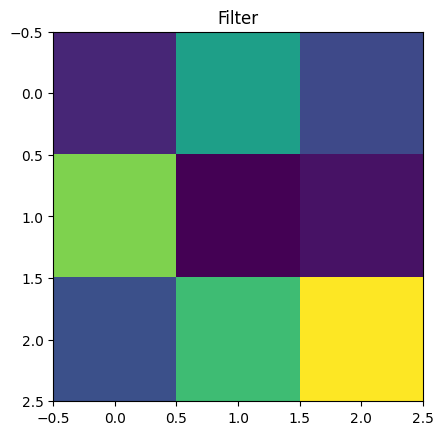

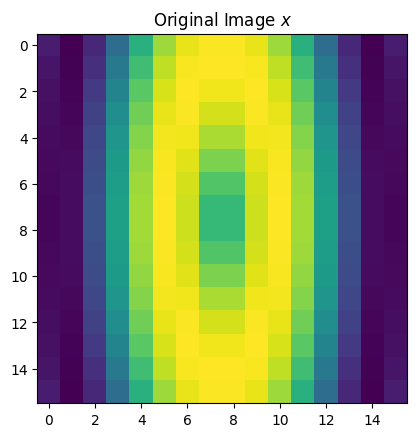

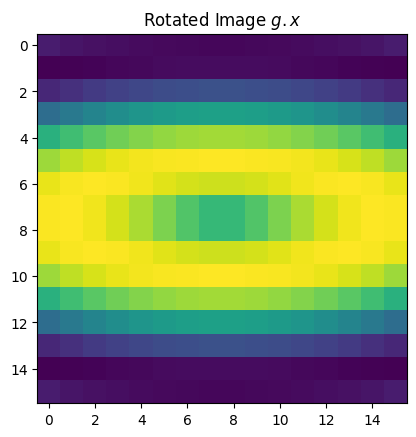

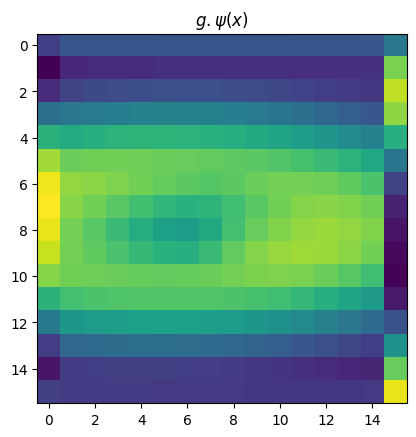

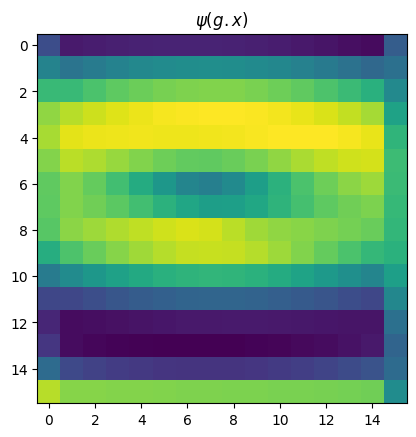

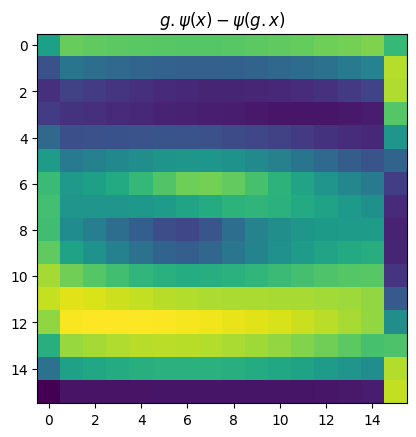

In [ ]:
filter3x3 = torch.randn(1, 1, 3, 3)

plt.imshow(filter3x3[0, 0].numpy())
plt.title('Filter')
plt.show()

# generate some input...
xs = torch.linspace(-5, 5, steps=16)
xg, yg = torch.meshgrid(xs, xs, indexing='xy')
x = torch.sin(torch.sqrt(xg * xg + yg/3. * yg/3.))
x = x[None, None, ...]

r = 1
gx = rotate(x, r)

plt.imshow(x[0, 0].numpy())
plt.title('Original Image $x$')
plt.show()

plt.imshow(gx[0, 0].numpy())
plt.title('Rotated Image $g.x$')
plt.show()

# ...then test equivariance:
psi_x = torch.conv2d(x, filter3x3, bias=None, padding=1)
psi_gx = torch.conv2d(gx, filter3x3, bias=None, padding=1)

g_psi_x = rotate(psi_x, r)

plt.imshow(g_psi_x[0, 0].numpy())
plt.title('$g.\\psi(x)$')
plt.show()

plt.imshow(psi_gx[0, 0].numpy())
plt.title('$\\psi(g.x)$')
plt.show()

plt.imshow((g_psi_x-psi_gx)[0, 0].numpy())
plt.title('$g.\\psi(x)-\\psi(g.x)$')
plt.show()

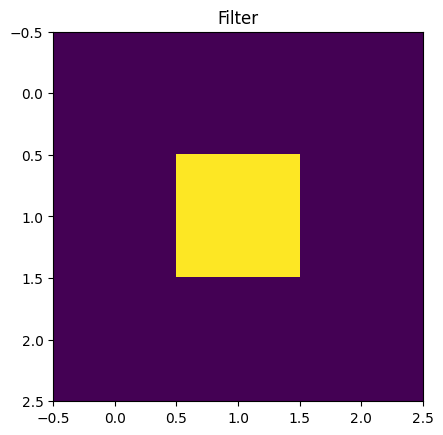

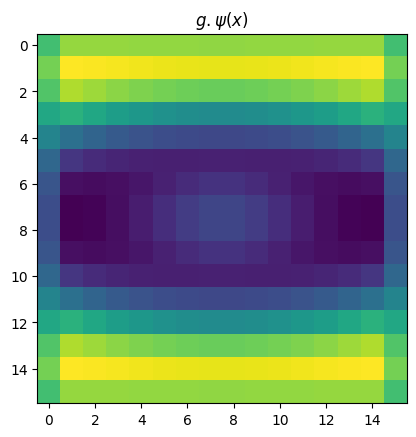

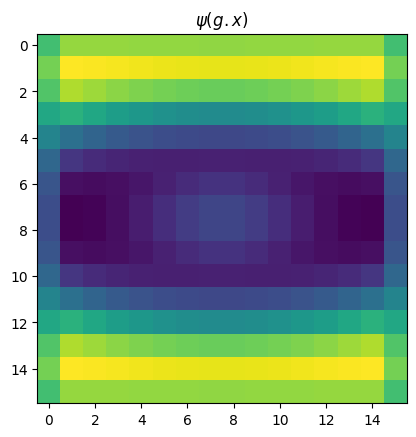

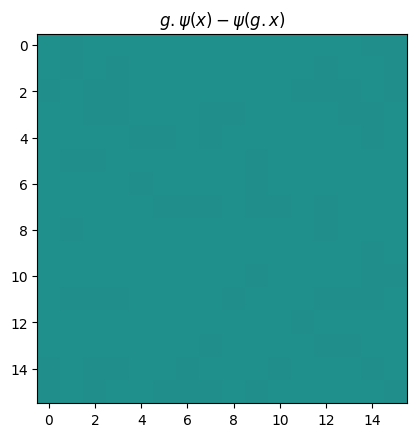

In [ ]:
filter3x3 = torch.empty((1, 1, 3, 3))
# fill the central pixel
filter3x3[0, 0, 1, 1] = np.random.randn()
# fill the ring of radius 1 around it with a unique value
mask = torch.ones(3, 3, dtype=torch.bool)
mask[1, 1] = 0
filter3x3[0, 0, mask] = np.random.randn()

plt.imshow(filter3x3[0, 0].numpy())
plt.title('Filter')
plt.show()


psi_x = torch.conv2d(x, filter3x3, bias=None, padding=1)
psi_gx = torch.conv2d(gx, filter3x3, bias=None, padding=1)

g_psi_x = rotate(psi_x, r)

plt.imshow(g_psi_x[0, 0].numpy())
plt.title('$g.\\psi(x)$')
plt.show()

plt.imshow(psi_gx[0, 0].numpy())
plt.title('$\\psi(g.x)$')
plt.show()

plt.imshow((g_psi_x-psi_gx)[0, 0].numpy(), vmin=-0.1, vmax=0.1)
plt.title('$g.\\psi(x)-\\psi(g.x)$')
plt.show()

# Lifting convolution layer

Let $X$ be the space of 2D images on a grid of pixels $\mathbf{p} \in \mathbb{Z}^2$.
Let now $\psi \in X$ be a filter and $x \in X$ an input image.
The *lifting* convolution of $\psi \star x: X\times X\rightarrow X'\times G$ is defined as:
$$
  [\psi \star x](\mathbf{t}, r) := \sum_{\mathbf{p} \in \mathbb{Z}^2} \psi((\mathbf{t}, r)^{-1} \mathbf{p})\ x(\mathbf{p})
                                 = \sum_{\mathbf{p} \in \mathbb{Z}^2} \psi(r^{-1} (\mathbf{p} - \mathbf{t}))\ x(\mathbf{p}),
$$
where $t$ are translations on $\mathbf{Z}^2$ and $r \in G$ are rotations.
Note that the output of the lifting convolution is not anymore an 2D image in $X$.
It is now a function over the group $C_4$ we consider.

In [9]:
class LiftingConv2d(torch.nn.Module):

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, padding: int = 0):

        super(LiftingConv2d, self).__init__()

        self.kernel_size = kernel_size
        self.stride = 1
        self.dilation = 1
        self.padding = padding
        self.out_channels = out_channels
        self.in_channels = in_channels

        # let's create a tensor which stores the learnable filters
        # this layer have `out_channels x in_channels` different learnable filters, each of shape `kernel_size x kernel_size`
        randn_t = torch.randn(self.out_channels, self.in_channels, self.kernel_size, self.kernel_size)
        self.weight = torch.nn.Parameter(randn_t/np.sqrt(self.out_channels * self.in_channels), requires_grad=True)

        # bias is shared over the 4 rotations
        # it has `out_channels` learnable parameters, one for each independent output
        self.bias = torch.nn.Parameter(torch.zeros(self.out_channels), requires_grad=True)

    def build_filter(self):

        # now we build the bigger filter of shape `out_channels x 4 x in_channels x kernel_size x kernel_size` by rotating 4 times
        # it should contain the learnable filter rotated `r` times
        _filter = torch.stack([rotate(self.weight, r) for r in range(4)], dim=1)  # stack concateantes along a new dimension dim

        # now build the `_bias[:, i]` should contain a copy of the learnable bias for each `i=0,1,2,3`
        _bias = torch.stack([self.bias for r in range(4)], dim=1)
        return _filter, _bias

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        _filter, _bias = self.build_filter()

        assert _bias.shape == (self.out_channels, 4)
        assert _filter.shape == (self.out_channels, 4, self.in_channels, self.kernel_size, self.kernel_size)

        # to be able to use torch.conv2d, we need to reshape the filter and bias to stack together all filters
        _filter = _filter.reshape(self.out_channels * 4, self.in_channels, self.kernel_size, self.kernel_size)
        _bias = _bias.reshape(self.out_channels * 4)

        out = torch.conv2d(x, _filter,
                        stride=self.stride,
                        padding=self.padding,
                        dilation=self.dilation,
                        bias=_bias)
        # `out` has now shape `batch_size x out_channels*4 x W x H`
        # we need to reshape it to `batch_size x out_channels x 4 x W x H` to have the shape we expect
        return out.view(-1, self.out_channels, 4, out.shape[-2], out.shape[-1])

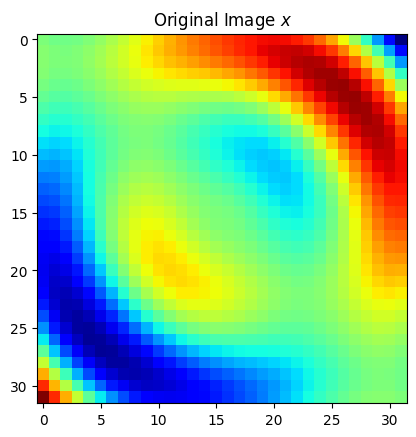

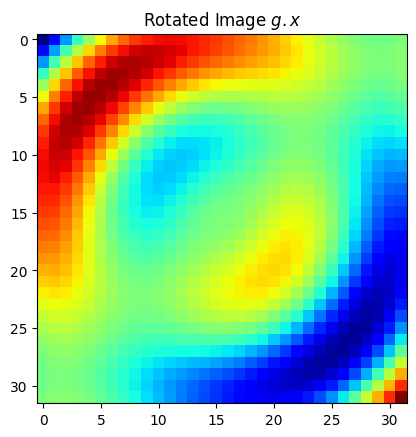

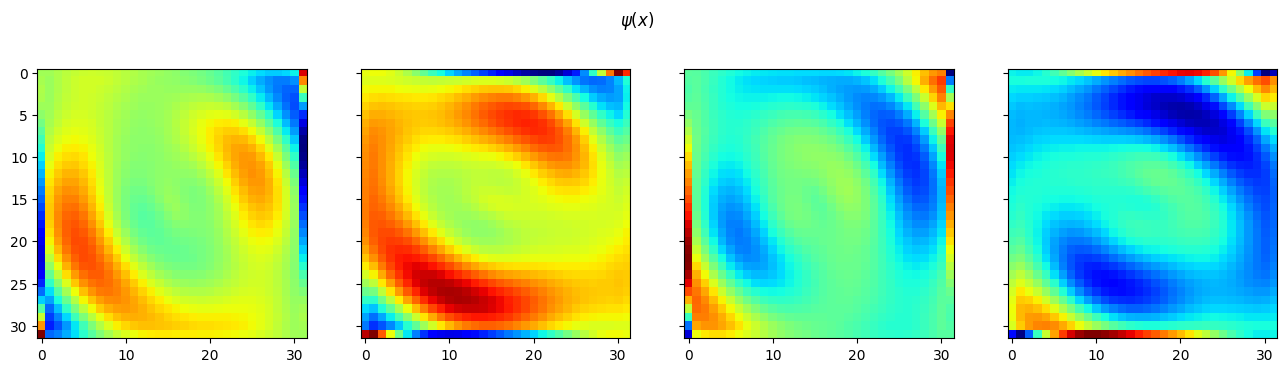

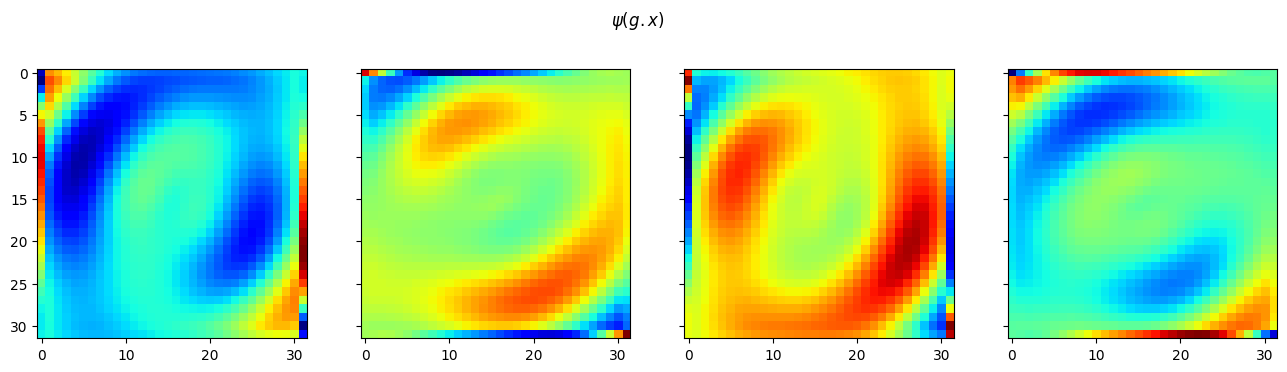

In [ ]:
# Let's check if the layer is really equivariant

in_channels = 1
out_channels = 10
kernel_size = 3
batchsize = 1
S = 32

layer = LiftingConv2d(in_channels=in_channels, out_channels=out_channels, kernel_size = kernel_size, padding=1)
layer.eval()


# generate some input...
xs = torch.linspace(-5, 5, steps=S)
xg, yg = torch.meshgrid(xs, xs, indexing='xy')
x = torch.sin(torch.sqrt(xg * xg + yg * yg))*(yg-xg)/10.

x = x[None, None, ...]
gx = rotate(x, 1)

plt.imshow(x[0, 0].numpy(), cmap='jet')
plt.title('Original Image $x$')
plt.show()

plt.imshow(gx[0, 0].numpy(), cmap='jet')
plt.title('Rotated Image $g.x$')
plt.show()

# compute the output
psi_x = layer(x)
psi_gx = layer(gx)

assert psi_x.shape == (batchsize, out_channels, 4, S, S)

fig, axes = plt.subplots(1, 4, sharex=True, sharey=True, squeeze=True, figsize=(16, 4))
for i in range(4):
  axes[i].imshow(psi_x[0, 0, i].detach().numpy(), cmap='jet')
fig.suptitle('$\\psi(x)$')
plt.show()

fig, axes = plt.subplots(1, 4, sharex=True, sharey=True, squeeze=True, figsize=(16, 4))
for i in range(4):
  axes[i].imshow(psi_gx[0, 0, i].detach().numpy(), cmap='jet')
fig.suptitle('$\\psi(g.x)$')
plt.show()

# check the model has the right number of parameters
assert layer.weight.numel() == in_channels * out_channels * kernel_size**2
assert layer.bias.numel() == out_channels

 # Group convolution layer

To extend the lifting convolution to form mapping $X\times G \rightarrow X'\times G$ we define the full *group convolution* layer as follows:
$$
  [\psi \star x](\mathbf{t}, r) := \sum_{s \in C_4} \sum_{\mathbf{p} \in \mathbb{Z}^2} \psi((\mathbf{t}, r)^{-1} (\mathbf{p}, s))\ x(\mathbf{p}, s)
$$
By using the fact that $[(\mathbf{t},r).\psi](\mathbf{p}, s)=\psi((\mathbf{t}, r)^{-1} (\mathbf{p}, s)) = \psi(r^{-1} (\mathbf{p} - \mathbf{t}), r^{-1}s)=[r.\psi](\mathbf{p} - \mathbf{t}, r^{-1}s)$
the equation becomes:
$$
  [\psi \star x](\mathbf{t}, r) := \sum_{s \in C_4} \sum_{\mathbf{p} \in \mathbb{Z}^2} [r.\psi](\mathbf{p} - \mathbf{t}, r^{-1}s)\ x(\mathbf{p}, s).
$$
Note additional group index $s$ on the RHS.

In [10]:
class GroupConv2d(torch.nn.Module):

    def __init__(self, in_channels: int, out_channels: int, kernel_size: int, padding: int = 0):

        super(GroupConv2d, self).__init__()

        self.kernel_size = kernel_size
        self.stride = 1
        self.dilation = 1
        self.padding = padding
        self.out_channels = out_channels
        self.in_channels = in_channels

        # this layer should have `out_channels x in_channels` different learnable filters, each of shape `4 x kernel_size x kernel_size`
        randn_t = torch.randn(self.out_channels, self.in_channels, 4, self.kernel_size, self.kernel_size)
        self.weight = torch.nn.Parameter(randn_t/np.sqrt(self.out_channels * self.in_channels), requires_grad=True)

        # bias is shared over the 4 rotations
        # it has `out_channels` learnable parameters, one for each independent output
        self.bias = torch.nn.Parameter(torch.zeros(self.out_channels), requires_grad=True)

    def build_filter(self):

        # now we build the bigger filter of shape `out_channels x 4 x in_channels x 4 x kernel_size x kernel_size` by rotating 4 times
        # it should contain the learnable filter rotated `r` times
        _filter = torch.stack([rotate(self.weight, r).roll(r, dims=-3) for r in range(4)], dim=1)  # stack concateantes along a new dimension dim

        # now build the `_bias[:, i]` should contain a copy of the learnable bias for each `i=0,1,2,3`
        _bias = torch.stack([self.bias for r in range(4)], dim=1)

        return _filter, _bias

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        _filter, _bias = self.build_filter()

        assert _bias.shape == (self.out_channels, 4)
        assert _filter.shape == (self.out_channels, 4, self.in_channels, 4, self.kernel_size, self.kernel_size)

        # to be able to use torch.conv2d, we need to reshape the filter and bias to stack together all filters
        _filter = _filter.reshape(self.out_channels * 4, self.in_channels * 4, self.kernel_size, self.kernel_size)
        _bias = _bias.reshape(self.out_channels * 4)

        # this time, also the input has shape `batch_size x in_channels x 4 x W x H`
        # so we need to reshape it to `batch_size x in_channels*4 x W x H` to be able to use torch.conv2d
        x = x.view(x.shape[0], self.in_channels*4, x.shape[-2], x.shape[-1])

        out = torch.conv2d(x, _filter,
                        stride=self.stride,
                        padding=self.padding,
                        dilation=self.dilation,
                        bias=_bias)

        # `out` has now shape `batch_size x out_channels*4 x W x H`
        # we need to reshape it to `batch_size x out_channels x 4 x W x H` to have the shape we expect
        return out.view(-1, self.out_channels, 4, out.shape[-2], out.shape[-1])

# Tasks to do
1. Show that a convolutional layer is translationally equivariant using your own images;
- what about stacking several layers into a CNN?
2. In the same way, verify that a standard CNN is not rotationally equivariant.
3. Explain how a group-convolutional layer works:
- start with analyzing and plotting how the filters are constructed;
- remember that group action in composite space $X\times G$ is operation on $X$ (rotation) followed by translation along the group $G$ axis (cyclic permutation), i.e., `gx = rotate(x, 1).roll(1, dims=-3)`.
4. Check equivariance for that layer:
- using your own input;
- how to construct a rotationally equivariant output in this case?
5. **Final task.**
Classify quantum number $n$ from images of hydrogen wave-function (e.g. *Re* part --  see below), and compare the performance of standard CNN with that of $C_4$-equivariant CNN:
- generate datasets of 1000/500/500 train/val/test images, with three classes corresponding to (n=2,3,4). Randomize the remaining quantum numbers (l,m), the Bohr-radius scaling parameter (a_0), and the orbital orientation.
- Train both architectures using the same datasets and comparable training procedures. Use the C4CNN architecture defined below. Vary the number of channels in both networks to obtain models with **comparable no. of parameters**.
- Compare test accuracy as a function of the number of trainable parameters.

# Some additional code

In [ ]:
class C4CNN(torch.nn.Module):
    def __init__(self, n_classes=10):

        super(C4CNN, self).__init__()
        in_channels = 1
        channels = [8, 16, 32, 64, 128]
        kernel_size = 3

        self.lifting = LiftingConv2d(in_channels=in_channels, out_channels=channels[0], kernel_size = kernel_size, padding=1)
        self.hidden_layers = torch.nn.ModuleList(
            [
                torch.nn.Sequential(
                    GroupConv2d(in_channels=channels[nc], out_channels=channels[nc+1], kernel_size = kernel_size, padding=1),
                    torch.nn.MaxPool3d(kernel_size=(1,3,3), stride=(1,2,2), padding=(0,1,1)),
                    torch.nn.ReLU()
                ) for nc in range(len(channels[:-1]) - 1)
            ]
        )
        self.output_layer = torch.nn.Sequential(
                    GroupConv2d(in_channels=channels[-2], out_channels=channels[-1], kernel_size = kernel_size, padding=1),
                    torch.nn.MaxPool3d(kernel_size=(4,3,3), stride=(1,1,1), padding=(0,0,0)),
                    torch.nn.ReLU())

    def forward(self, x):
        x = self.lifting(x)
        for layer in self.hidden_layers:
            x = layer(x)
        return self.output_layer(x)

net = C4CNN()

x = torch.randn(5, 1, 33, 33)
gx = rotate(x, 1)
y = net(x)
gy = net(gx)
print(y.shape)

plt.imshow(y[2, 33, 0].detach().numpy(), cmap='jet')
plt.title('$\\Psi(x)$')
plt.show()
plt.imshow(gy[2, 33, 0].detach().numpy(), cmap='jet')
plt.title('$\\Psi(g.x)$')
plt.show()

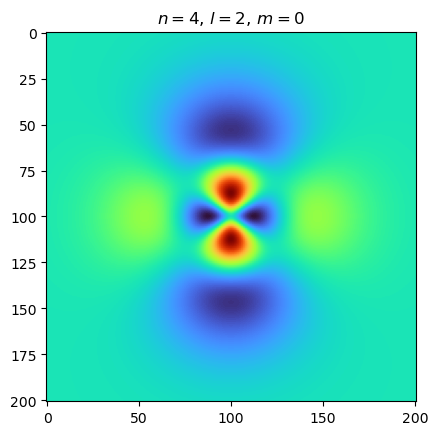

In [ ]:
import numpy as np
from scipy.special import factorial, sph_harm, assoc_laguerre
from random import randrange, random

def hydrogen_wavefunction(n, l, m, r, theta, phi, a0=1.0):
    """
    Calculates the hydrogen atom wavefunction psi_nlm(r, theta, phi).

    Args:
        n (int): Principal quantum number.
        l (int): Angular momentum quantum number.
        m (int): Magnetic quantum number.
        r (float): Radial coordinate.
        theta (float): Polar angle.
        phi (float): Azimuthal angle.
        a0 (float): Bohr radius (default is 1.0 for simplicity).

    Returns:
        complex: The complex wavefunction value.
    """
    # Radial part R_nl(r)
    rho = r*2/n/a0
    term1 = np.sqrt((2/n/a0)**3*factorial(n-l-1)/factorial(n+l)/n/2)
    term2 = rho**l
    term3 = np.exp(-rho/2)
    term4 = assoc_laguerre(rho, n-l-1, 2*l+1)
    R_nl = term1*term2*term3*term4

    # Angular part Y_lm(theta, phi)
    Y_lm = sph_harm(m, l, phi, theta)

    # Full wavefunction psi_nlm(r, theta, phi)
    psi = R_nl*Y_lm
    return psi

ys = np.linspace(-1., 1., num=201)
yg, zg = np.meshgrid(ys, ys)

r = np.sqrt(yg**2 + zg**2)
theta = np.arctan2(yg, zg)
phi = np.zeros_like(theta)

n = 4
l = 2
m = 0

rand_a = random() * 0.08 + 0.02
rand_k = randrange(4)

psi = hydrogen_wavefunction(n, l, m, r, theta, phi, rand_a)

image = np.real(psi)
image = np.rot90(image, k=rand_k).copy()
image /= np.max(np.abs(image)) + 1e-8

plt.imshow(image, cmap="turbo")
plt.title(rf"$n={n},\,l={l},\,m={m}$")
plt.show()